## Setup

**Notebook produces RMSE vs Leadtime**


In [2]:
import os, sys

# Make the ecCodes DLL findable (must run BEFORE importing xarray/cfgrib)
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

import xarray as xr
import cfgrib
import snotelpy as sp
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from datetime import datetime
import pandas as pd
from ens import load_forecast, forecast_basin, observed_gain, score_members

### Config

In [3]:

# La Nina event matches test file currently 
events = pd.DataFrame([
    {"phase": "La Nina",  "winter": "2021-22", "target_start": "2022-01-10", "target_end": "2022-01-17"},
    {"phase": "El Nino",  "winter": "XXXX-XX", "target_start": "XXXX-XX-XX", "target_end": "XXXX-XX-XX"},  # placeholder
    {"phase": "Neutral",  "winter": "XXXX-XX", "target_start": "XXXX-XX-XX", "target_end": "XXXX-XX-XX"},  # placeholder
])

EVENT = 0 # 0 for la nina, 1 for el nino, 2 for neutral

# Lead times (weeks before the start of the target window)
LEAD_WEEKS = [1, 2, 3, 4]


# ECMWF S2S init weekdays (Mon=0, Thu=3). VERIFY against the current S2S docs.
INIT_WEEKDAYS = [0, 3]

#snotel
SNOTEL_STATIONS = ["842:CO:SNTL"]     # swap for a list of basin stations later HUC = 
SNOTEL_ELEMENT  = ['WTEQ']
START_DATE ='2021-12-10',
END_DATE ='2022-01-20'

SNOTEL_CACHE    = "842_CO_SNTL_data_47.nc"     # fetch once, then load from disk


# Forecast
FORECAST_VAR   = "sf"                 # snowfall water equivalent, accumulated, kg m-2
MM_PER_INCH    = 25.4                 # 1 kg m-2 = 1 mm water
GRIB_DIR       = "."                  # where the .grib files live




START_DATE='2021-12-16' #snotel date range
END_DATE='2022-01-31'




## Observations (snotel)

#### Pull Your data only do this once

In [18]:
ds = sp.fetch_snotel(stations=SNOTEL_STATIONS, elements=SNOTEL_ELEMENT, duration="DAILY",start_date='2021-12-10',end_date='2022-01-20',include_coords=True)



sp.save_data(ds, 'NINA_snotel_obs')



JSONDecodeError: Expecting value: line 1 column 1 (char 0)

#### Load CACHE/data from last step

In [4]:
observations_raw = xr.open_dataset(SNOTEL_CACHE)

observations_raw


<xarray.Dataset> Size: 820B
Dimensions:    (time: 47, station: 1)
Coordinates:
  * time       (time) datetime64[ns] 376B 2021-12-16 2021-12-17 ... 2022-01-31
  * station    (station) <U11 44B '842:CO:SNTL'
    latitude   (station) float64 8B ...
    longitude  (station) float64 8B ...
    elevation  (station) float64 8B ...
Data variables:
    WTEQ       (time, station) float64 376B ...
Attributes:
    source:    USDA NRCS AWDB REST API
    network:   SNOTEL
    duration:  Daily

Get Snotels Basin Coords

In [ ]:



obs_lat = [float(min(observations_raw['latitude'].values - 1.5)), float(max(observations_raw['latitude'].values) + 1.5)]
obs_lon = [float((min(observations_raw['longitude'].values - 1.5) % 360)), float((max(observations_raw['longitude'].values) + 1.5) % 360)]
print(obs_lat)
print(obs_lon)

 


[38.11765, 41.11765]
[252.11981, 255.11981]


## Combine Basin into 1 series

In [6]:
basin_obs = observations_raw.mean(dim= "station")

basin_obs

<xarray.Dataset> Size: 752B
Dimensions:  (time: 47)
Coordinates:
  * time     (time) datetime64[ns] 376B 2021-12-16 2021-12-17 ... 2022-01-31
Data variables:
    WTEQ     (time) float64 376B 4.1 4.2 4.2 4.2 4.2 ... 10.5 10.6 10.6 10.6
Attributes:
    source:    USDA NRCS AWDB REST API
    network:   SNOTEL
    duration:  Daily

## Forecast loading

In [7]:
sf_raw = load_forecast(r"DATA\986f437998cb2c67bd913875435801ff.grib")

c:\Users\tatev\miniforge3\envs\atoc\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)


### Bound the forecast by snotel basin coords

In [8]:
                   
basin_fc = forecast_basin(ds = sf_raw,target_end=events.target_end[EVENT], target_start=events.target_start[EVENT],lat_bounds=obs_lat, lon_bounds=obs_lon)
basin_fc

<xarray.DataArray 'sf' (number: 50)> Size: 200B
array([0.5492588 , 0.05459523, 0.4692114 , 0.22222564, 0.4732868 ,
       0.8481483 , 0.28443342, 0.14271654, 0.81938976, 0.2865177 ,
       0.7300381 , 0.440991  , 0.1613346 , 0.69643515, 0.25682825,
       0.2691314 , 0.5002768 , 0.23552842, 1.071835  , 0.28243417,
       0.2389887 , 0.1564062 , 0.56056225, 0.43214813, 0.36363494,
       0.22791585, 0.14326744, 0.54526025, 0.4024668 , 0.22422491,
       0.01415012, 0.2951218 , 0.20430918, 0.40508136, 0.9076649 ,
       0.9650307 , 0.75979644, 0.23452878, 0.0578248 , 0.34379616,
       0.38270485, 0.08929282, 0.8966793 , 1.7943376 , 0.22376356,
       0.27805117, 0.02883551, 0.57209647, 0.4745968 , 0.46521297],
      dtype=float32)
Coordinates:
  * number   (number) int64 400B 1 2 3 4 5 6 7 8 9 ... 43 44 45 46 47 48 49 50
    time     datetime64[ns] 8B 2021-12-16
    surface  float64 8B 0.0
Attributes: (12/31)
    GRIB_paramId:                             228144
    GRIB_dataType:                            pf
    GRIB_numberOfPoints:                      20
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_shortName:                           sf
    GRIB_totalNumber:                         51
    GRIB_units:                               kg m**-2
    long_name:                                Snowfall water equivalent
    units:                                    kg m**-2
    standard_name:                            unknown

In [11]:

obs_gain  = observed_gain(snotel= observations_raw,target_start= events.target_start[EVENT], target_end= events.target_end[EVENT])
print(float(obs_gain))

0.1999999999999993


In [16]:
score_members(members=basin_fc,obs =  obs_gain)

Ensemble mean Error: 0.22964741587638926
Rank of Obs: 0.18
STD: 0.32335522770881653


### Plotting

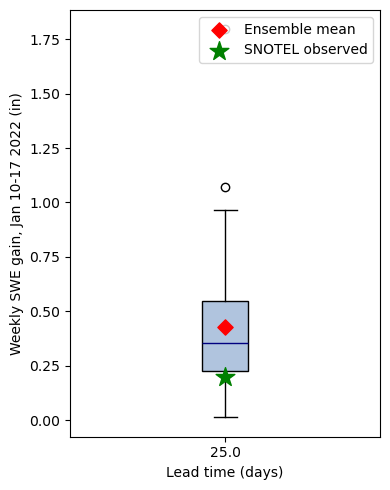

In [17]:
fig, ax = plt.subplots(figsize=(4, 5))

lead_wk =  ((np.datetime64(events.target_start[EVENT]) - sf_raw.time.values) / np.timedelta64(1, 'D')) 

ax.boxplot(basin_fc.values, positions=[lead_wk], widths=0.3,
           showfliers=True, patch_artist=True,
           boxprops=dict(facecolor="lightsteelblue"),
           medianprops=dict(color="navy"))

ax.scatter(lead_wk, float(basin_fc.mean()), color="red", marker="D", s=60, zorder=3, label="Ensemble mean")
ax.scatter(lead_wk, obs_gain, color="green", marker="*", s=200, zorder=3, label="SNOTEL observed")

ax.set_xlim(lead_wk - 1, lead_wk + 1)
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Weekly SWE gain, Jan 10-17 2022 (in)")
ax.legend()
plt.tight_layout()
plt.show()



Run it for all of lead times

First load all datasets for phase:

In [ ]:
#La NINA
week4_fc = load_forecast()
week3_fc = load_forecast()
week2_fc = load_forecast()
week1_fc = load_forecast()





